In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import joblib

print("All required libraries imported successfully.")

All required libraries imported successfully.


In [2]:
# Load the diabetes dataset
df = pd.read_csv("diabetes.csv")

# Display the first five rows
print("First 5 rows of the dataset:")
display(df.head())

# Display the dataset shape
print("\nDataset shape:", df.shape)

# Display the column names
print("\nColumn names:")
print(df.columns.tolist())

First 5 rows of the dataset:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1



Dataset shape: (768, 9)

Column names:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']


In [3]:
# Display dataset information
print("Dataset Information:")
df.info()

# Check for missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check the distribution of diabetes outcomes
print("\nOutcome Distribution:")
print(df["Outcome"].value_counts())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

Missing Values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age

In [4]:
# Columns where zero may represent a missing measurement
columns_with_zero = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

# Replace zero values with missing values
df[columns_with_zero] = df[columns_with_zero].replace(0, np.nan)

# Display missing values after replacement
print("Missing values after replacing unrealistic zeros:")
print(df.isnull().sum())

Missing values after replacing unrealistic zeros:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


In [5]:
# Fill missing values using the median of each column
for column in columns_with_zero:
    df[column] = df[column].fillna(df[column].median())

# Check missing values again
print("Missing values after median imputation:")
print(df.isnull().sum())

Missing values after median imputation:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [6]:
# Separate features (X) and target (y)
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

# Display the features
print("Features (X):")
display(X.head())

# Display the target
print("\nTarget (y):")
print(y.head())

print("\nNumber of features:", X.shape[1])
print("Number of target values:", y.shape[0])

Features (X):


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6,148.0,72.0,35.0,125.0,33.6,0.627,50
1,1,85.0,66.0,29.0,125.0,26.6,0.351,31
2,8,183.0,64.0,29.0,125.0,23.3,0.672,32
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33



Target (y):
0    1
1    0
2    1
3    0
4    1
Name: Outcome, dtype: int64

Number of features: 8
Number of target values: 768


In [7]:
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display the shapes of the datasets
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training data shape: (614, 8)
Testing data shape: (154, 8)
Training target shape: (614,)
Testing target shape: (154,)


In [8]:
# Create a StandardScaler
scaler = StandardScaler()

# Fit the scaler on training data and transform it
X_train = scaler.fit_transform(X_train)

# Transform the testing data using the same scaler
X_test = scaler.transform(X_test)

print("Feature scaling completed successfully.")
print("Scaled training data shape:", X_train.shape)
print("Scaled testing data shape:", X_test.shape)

Feature scaling completed successfully.
Scaled training data shape: (614, 8)
Scaled testing data shape: (154, 8)


In [9]:
# Create the Logistic Regression model
model = LogisticRegression(random_state=42, max_iter=1000)

# Train the model using training data
model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [10]:
# Predict outcomes for the testing data
y_pred = model.predict(X_test)

print("Predictions made successfully!")

print("\nFirst 10 predictions:")
print(y_pred[:10])

Predictions made successfully!

First 10 predictions:
[1 0 0 0 0 0 0 1 0 1]


In [11]:
# Evaluate the model's performance

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Model Evaluation Results")
print("------------------------")
print("Accuracy :", round(accuracy * 100, 2), "%")
print("Precision:", round(precision, 2))
print("Recall   :", round(recall, 2))
print("F1 Score :", round(f1, 2))

# Display the confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

# Display the classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Model Evaluation Results
------------------------
Accuracy : 70.78 %
Precision: 0.6
Recall   : 0.5
F1 Score : 0.55

Confusion Matrix:
[[82 18]
 [27 27]]

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.82      0.78       100
           1       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154



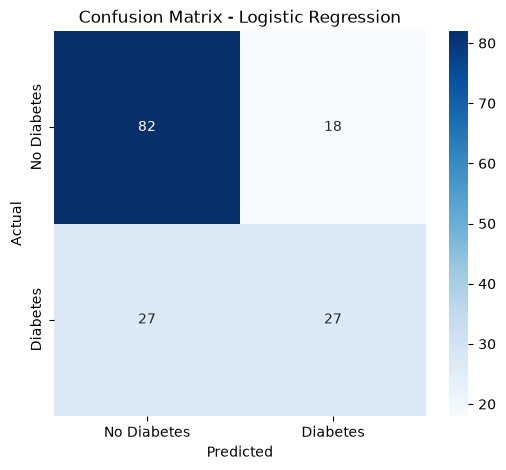

In [12]:
# Plot the confusion matrix

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Diabetes", "Diabetes"],
    yticklabels=["No Diabetes", "Diabetes"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Logistic Regression")

plt.show()

In [13]:
import pandas as pd
import numpy as np

df = pd.read_csv("diabetes.csv")

print("Dataset loaded successfully!")
print(df.head())
print("Dataset shape:", df.shape)

Dataset loaded successfully!
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  
Dataset shape: (768, 9)


In [14]:
# Replace unrealistic zero values with missing values
columns_with_zero = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

df[columns_with_zero] = df[columns_with_zero].replace(0, np.nan)

# Fill missing values with the median
for column in columns_with_zero:
    df[column] = df[column].fillna(df[column].median())

print("Dataset cleaned successfully!")
print("Missing values remaining:", df.isnull().sum().sum())

Dataset cleaned successfully!
Missing values remaining: 0


In [15]:
# Separate features and target
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

print("Features and target separated successfully!")
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features and target separated successfully!
Features shape: (768, 8)
Target shape: (768,)


In [16]:
# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Data split successfully!")
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Data split successfully!
Training data shape: (614, 8)
Testing data shape: (154, 8)


In [17]:
from sklearn.preprocessing import StandardScaler

print("StandardScaler imported successfully!")

StandardScaler imported successfully!


In [18]:
# Standardize the features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Data standardized successfully!")
print("Scaled training data shape:", X_train_scaled.shape)
print("Scaled testing data shape:", X_test_scaled.shape)

Data standardized successfully!
Scaled training data shape: (614, 8)
Scaled testing data shape: (154, 8)


In [19]:
from sklearn.linear_model import LogisticRegression

print("LogisticRegression imported successfully!")

LogisticRegression imported successfully!


In [20]:
model = LogisticRegression(random_state=42, max_iter=1000)

model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [21]:
# Predict diabetes outcomes
y_pred = model.predict(X_test_scaled)

print("Predictions completed successfully!")
print("First 10 predictions:")
print(y_pred[:10])

Predictions completed successfully!
First 10 predictions:
[1 0 0 0 0 0 0 1 0 1]


In [22]:
# Predict diabetes outcomes
y_pred = model.predict(X_test_scaled)

print("Predictions completed successfully!")
print("First 10 predictions:")
print(y_pred[:10])

Predictions completed successfully!
First 10 predictions:
[1 0 0 0 0 0 0 1 0 1]


In [23]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("Evaluation functions imported successfully!")

Evaluation functions imported successfully!


In [24]:
# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Model Evaluation Results")
print("------------------------")
print(f"Accuracy: {accuracy * 100:.2f}%")
print(f"Precision: {precision:.2f}")
print(f"Recall: {recall:.2f}")
print(f"F1 Score: {f1:.2f}")

Model Evaluation Results
------------------------
Accuracy: 70.78%
Precision: 0.60
Recall: 0.50
F1 Score: 0.55


In [25]:
from sklearn.metrics import confusion_matrix

In [26]:
# Generate the confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[82 18]
 [27 27]]


In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

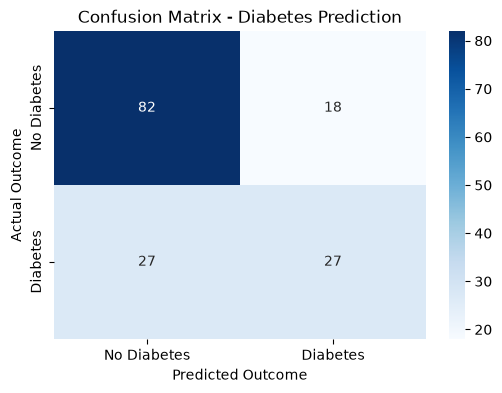

In [28]:
# Visualize the confusion matrix
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Diabetes", "Diabetes"],
    yticklabels=["No Diabetes", "Diabetes"]
)

plt.xlabel("Predicted Outcome")
plt.ylabel("Actual Outcome")
plt.title("Confusion Matrix - Diabetes Prediction")
plt.show()

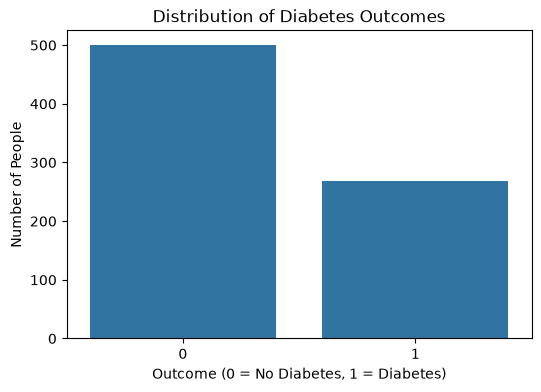

In [29]:
# Visualize diabetes outcome distribution
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Outcome")

plt.title("Distribution of Diabetes Outcomes")
plt.xlabel("Outcome (0 = No Diabetes, 1 = Diabetes)")
plt.ylabel("Number of People")

plt.show()

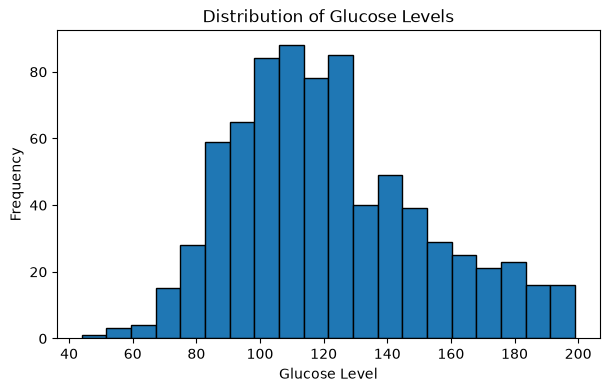

In [30]:
# Visualize glucose levels
plt.figure(figsize=(7, 4))

plt.hist(df["Glucose"], bins=20, edgecolor="black")

plt.title("Distribution of Glucose Levels")
plt.xlabel("Glucose Level")
plt.ylabel("Frequency")

plt.show()

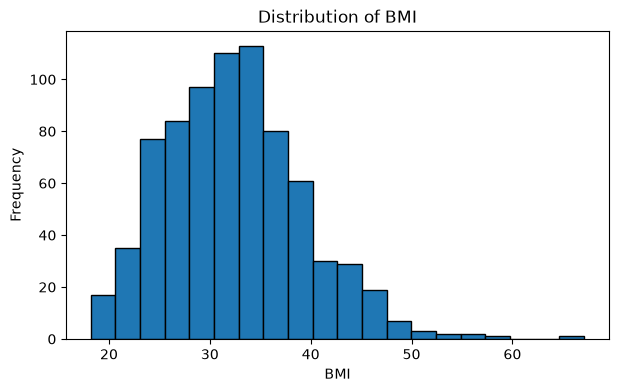

In [31]:
# Visualize BMI distribution
plt.figure(figsize=(7, 4))

plt.hist(df["BMI"], bins=20, edgecolor="black")

plt.title("Distribution of BMI")
plt.xlabel("BMI")
plt.ylabel("Frequency")

plt.show()

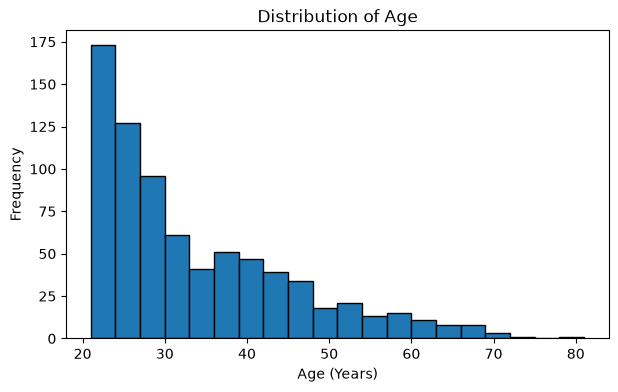

In [32]:
# Visualize age distribution
plt.figure(figsize=(7, 4))

plt.hist(df["Age"], bins=20, edgecolor="black")

plt.title("Distribution of Age")
plt.xlabel("Age (Years)")
plt.ylabel("Frequency")

plt.show()

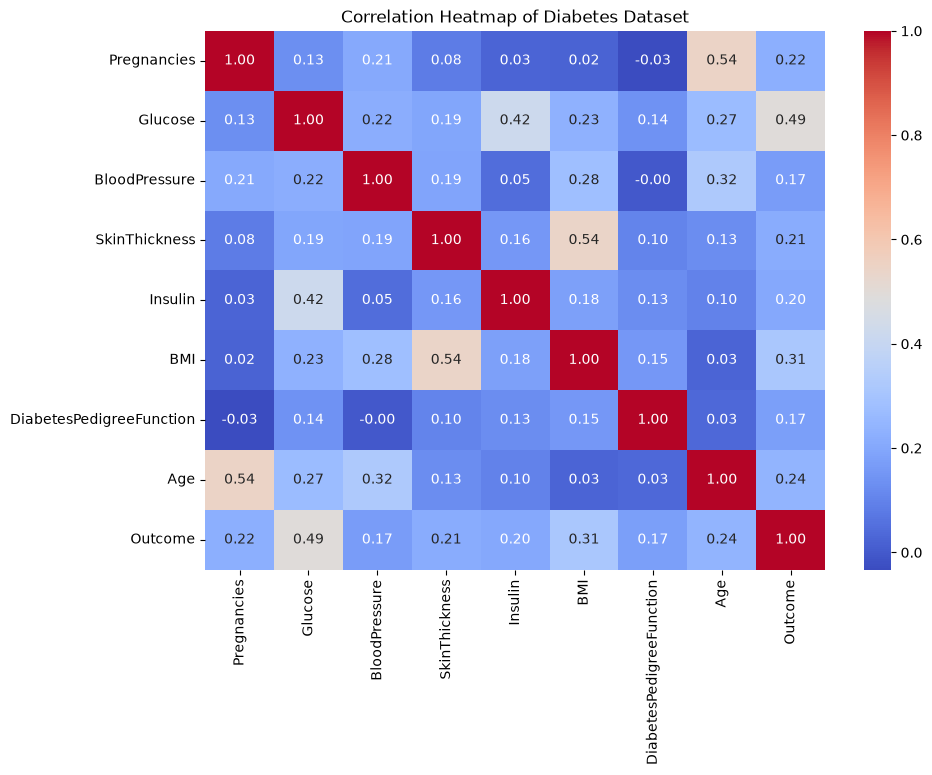

In [33]:
# Correlation heatmap
plt.figure(figsize=(10, 7))

correlation = df.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Diabetes Dataset")
plt.show()

## Actual vs Predicted Values

In [34]:
# Compare actual and predicted outcomes
comparison = pd.DataFrame({
    "Actual Outcome": y_test.values,
    "Predicted Outcome": y_pred
})

print("Actual vs Predicted Values:")
print(comparison.head(20))

Actual vs Predicted Values:
    Actual Outcome  Predicted Outcome
0                0                  1
1                0                  0
2                0                  0
3                1                  0
4                0                  0
5                0                  0
6                1                  0
7                1                  1
8                0                  0
9                0                  1
10               0                  0
11               1                  0
12               0                  0
13               0                  0
14               1                  0
15               1                  0
16               0                  1
17               0                  0
18               0                  1
19               0                  0


## Saving the Trained Model

In [35]:
# Save the trained model and scaler
import joblib

joblib.dump(model, "diabetes_logistic_model.pkl")
joblib.dump(scaler, "diabetes_scaler.pkl")

print("Model saved successfully!")
print("Scaler saved successfully!")

Model saved successfully!
Scaler saved successfully!


## Conclusion

In this project, a Diabetes Prediction System was developed using Machine Learning techniques. The Pima Indians Diabetes Dataset was used to train and test the model.

The dataset was preprocessed by handling unrealistic zero values and replacing them with the median values of the respective features. The dataset was then divided into training and testing sets. StandardScaler was used to standardize the features, and Logistic Regression was applied to build the prediction model.

The performance of the model was evaluated using accuracy, precision, recall, F1-score, and a confusion matrix. Different visualizations were also created to understand the dataset and the model's performance.

This project demonstrates how Artificial Intelligence and Machine Learning can support the early identification of potential diabetes risk. However, the model's predictions are not a substitute for professional medical diagnosis.

The project is related to Sustainable Development Goal 3 (SDG 3): Good Health and Well-Being.